# 03 · Match report walkthrough — team stats, player tracklets, timeline

Runs the analytics on a perception output folder (`outputs/<match>/tracks.csv`, `ball.csv`) — or on a
synthetic match if you have not processed a video yet — and walks through every output table and figure.
Definitions and reliability levels of each statistic: `docs/STATS_RULEBOOK.md`.

In [1]:
import sys, time, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
from football_eval.config import load_config
from football_eval.perception import load_perception
from football_eval.analytics import run_analytics, save_analytics
from football_eval.report import shot_map, possession_plot, heatmaps

MATCH_DIR = ROOT / "outputs/match1"          # <- output folder of run_analysis.py --video ...
CONFIG = ROOT / "configs/default.yaml"
cfg = load_config(CONFIG)
if (MATCH_DIR / "tracks.csv").exists():
    p = load_perception(str(MATCH_DIR)); tracks, ball = p["tracks"], p["ball"]
    sb = p.get("meta", {}).get("scoreboard_changes", [])
else:
    from football_eval.synthetic import SyntheticMatch, SynthConfig
    m = SyntheticMatch(SynthConfig(seed=7, period_s=1200, fragment_s=90)).generate()
    tracks, ball, sb = m["tracks"], m["ball"], []
    MATCH_DIR = ROOT / "outputs/synthetic_walkthrough"
    print("No perception output found -> using a synthetic match (2 × 20 min)")
r = run_analytics(tracks, ball, cfg, sb, root=str(ROOT))
ctx = r["ctx"]
print("periods (video s):", [(round(a), round(b)) for a, b in ctx.periods], "| attacks right:", ctx.attacks_right)

No perception output found -> using a synthetic match (2 × 20 min)
periods (video s): [(0, 1201), (1261, 2463)] | attacks right: [{0: True, 1: False}, {0: False, 1: True}]


## Team statistics

In [2]:
r["team_stats"].round(2)

,Team A,Team B
possession_%,47.52,52.48
ball_in_play_min,21.08,21.08
field_tilt_%,34.70,65.30
passes,162.00,178.00
passes_completed,128.00,146.00
pass_accuracy_%,79.01,82.02
progressive_passes,47.00,40.00
final_third_entries_pass,0.00,3.00
box_entries_pass,1.00,1.00
crosses,1.00,1.00


## Timeline of major events
`video_time` is the position in the file, `clock` the football clock (2nd half starts at 45').

In [3]:
tl = r["timeline"]
tl[tl.priority <= 3][["video_time", "clock", "team", "description"]]

,video_time,clock,team,description
1,00:43,1',Team A,Foul by Team A (free kick awarded)
2,02:08,3',Team A,Foul by Team A (free kick awarded)
3,03:12,4',Team A,Foul by Team A (free kick awarded)
4,03:30,4',Team A,GOAL Team A (xG 0.09) [from_shot]
5,03:30,4',Team A,"Shot Team A — goal, xG 0.09"
7,04:25,5',Team B,"Shot Team B — blocked, xG 0.03"
8,04:28,5',Team B,Foul by Team B (free kick awarded)
9,05:06,6',Team A,"Shot Team A — saved, xG 0.09"
10,05:56,6',Team B,"Shot Team B — blocked, xG 0.01"
11,06:02,7',Team B,"Shot Team B — goal, xG 0.04"


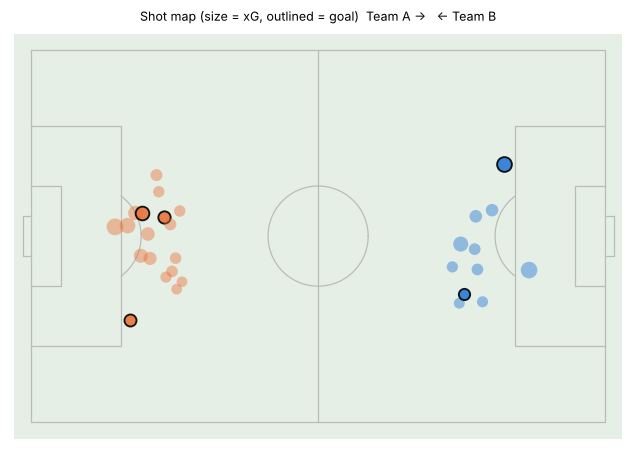

In [4]:
fig = shot_map(r["events"], ctx)

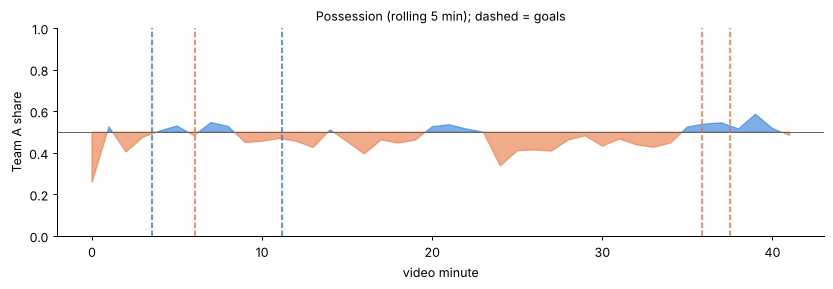

In [5]:
fig = possession_plot(r["possession_timeline"], ctx, r["events"])

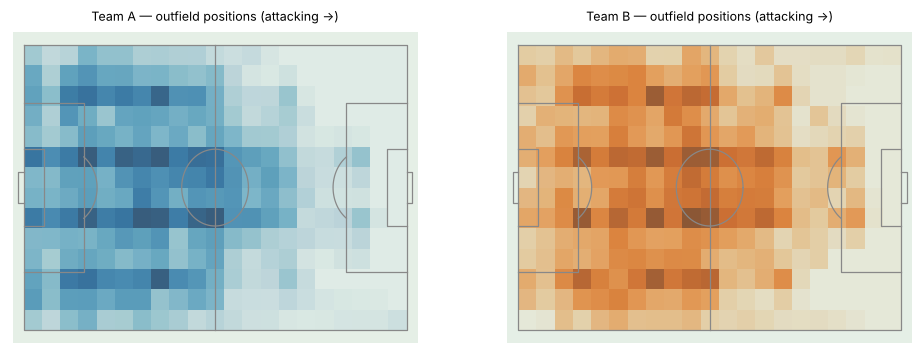

In [6]:
fig = heatmaps(r["tracks"], ctx)

## Player statistics (per tracklet)
Without jersey-number recognition a real player is split into several tracklets — use these for physical
profiles and as the input to future ID merging, not as final player stats.

In [7]:
r["player_stats"].head(12).round(2)

,team,role,first_t,last_t,minutes_tracked,distance_m,max_speed_kmh,avg_x,avg_y,touches,passes,passes_completed,shots,xG,goals,interceptions,recoveries
track_id,,,,,,,,,,,,,,,,,
6010,0,player,1182.8,1746.5,9.40,1093.82,36.17,69.48,54.21,1.0,1.0,1.0,0.0,0.00,0.0,0.0,0.0
3017,0,player,1498.5,2049.4,9.18,1210.34,35.09,90.67,42.14,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0
11016,0,player,1398.0,1942.2,9.07,1208.67,39.39,53.53,26.74,15.0,9.0,7.0,1.0,0.02,0.0,0.0,1.0
9008,0,player,801.7,1274.5,7.88,968.84,37.44,39.07,53.01,2.0,1.0,1.0,0.0,0.00,0.0,0.0,0.0
2016,0,player,1939.7,2369.2,7.16,974.97,35.95,88.68,56.96,1.0,1.0,1.0,0.0,0.00,0.0,0.0,0.0
1034,0,goalkeeper,1989.1,2402.5,6.89,399.72,25.88,101.35,33.82,3.0,3.0,2.0,0.0,0.00,0.0,0.0,0.0
6002,0,player,343.8,752.1,6.81,999.11,36.41,42.84,12.62,3.0,2.0,1.0,0.0,0.00,0.0,0.0,0.0
10005,0,player,677.2,1063.7,6.44,839.82,37.34,52.37,25.17,5.0,5.0,3.0,0.0,0.00,0.0,0.0,0.0
10007,0,player,1093.8,1473.1,6.32,650.72,38.55,48.61,36.11,10.0,7.0,3.0,0.0,0.00,0.0,1.0,0.0


## Event log (first rows) and stoppages

In [8]:
r["events"][["clock", "type", "team", "outcome", "x", "y", "xg", "detail"]].head(15)

,clock,type,team,outcome,x,y,xg,detail
0,1',pass,0,complete,52.800,33.475,NaN,
1,1',kickoff,0,NaN,52.395,34.013,NaN,period_start
2,1',pass,0,complete,44.953,29.872,NaN,progressive
3,1',pass,0,out,55.549,39.030,NaN,
4,1',throw_in,1,NaN,59.936,67.283,NaN,out
5,1',pass,1,complete,58.961,66.194,NaN,progressive|long
6,1',pass,1,complete,48.299,36.724,NaN,
7,1',pass,1,complete,53.857,59.593,NaN,
8,1',pass,1,complete,58.966,36.529,NaN,
9,1',foul_proxy,0,NaN,42.964,24.523,NaN,free_kick


In [9]:
st = r["stoppages"]
print(f"{len(st)} stoppages; ball in play {100 * (1 - r['dead'].mean()):.0f}% of the analysed time")
st.groupby("reason").dur.describe()[["count", "mean", "50%", "max"]]

72 stoppages; ball in play 51% of the analysed time


,count,mean,50%,max
reason,,,,
out,42.0,14.776,9.95,48.2
static,29.0,17.566,16.40,39.2
unseen,1.0,67.900,67.90,67.9


## Save everything (CSV + JSON + HTML report)

In [10]:
rep = save_analytics(r, str(MATCH_DIR), make_report=True)
print("report ->", rep.relative_to(ROOT))
print(sorted(p.name for p in MATCH_DIR.iterdir()))

report -> outputs/synthetic_walkthrough/report.html
['events.csv', 'match_context.json', 'player_stats.csv', 'report.html', 'stoppages.csv', 'team_stats.csv', 'timeline.csv', 'timeline.json']
